In [ ]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# PATHS
# =========================================================
DATASET_ROOT = Path("/kaggle/input/datasets/ahmedshayan1/liver-cancer-detection")
IMAGE_DIR = DATASET_ROOT / "train" / "images"
LABEL_DIR = DATASET_ROOT / "train" / "labels"
YAML_PATH = DATASET_ROOT / "data.yaml"

CLASS_NAMES = ['0', '1', '2']
IMG_EXTS = [".jpg", ".jpeg", ".png", ".bmp", ".webp"]

print("IMAGE_DIR exists:", IMAGE_DIR.exists(), IMAGE_DIR)
print("LABEL_DIR exists:", LABEL_DIR.exists(), LABEL_DIR)
print("YAML exists     :", YAML_PATH.exists(), YAML_PATH)

# =========================================================
# FIND ONE SAMPLE IMAGE FOR EACH CLASS
# =========================================================
sample_images = {}

for label_path in LABEL_DIR.glob("*.txt"):
    with open(label_path, "r") as f:
        lines = [line.strip() for line in f.readlines() if line.strip()]

    classes_in_file = set()

    for line in lines:
        parts = line.split()
        if len(parts) >= 3:   # class + at least one point pair
            class_id = int(float(parts[0]))
            classes_in_file.add(class_id)

    for class_id in classes_in_file:
        if class_id not in sample_images:
            for ext in IMG_EXTS:
                img_path = IMAGE_DIR / f"{label_path.stem}{ext}"
                if img_path.exists():
                    sample_images[class_id] = img_path
                    break

    if len(sample_images) == len(CLASS_NAMES):
        break

print("Found sample classes:", sample_images)

# =========================================================
# DRAW SEGMENTATION POLYGONS
# =========================================================
def draw_segmentation_polygons(image, label_path, class_names):
    h, w = image.shape[:2]

    with open(label_path, "r") as f:
        lines = [line.strip() for line in f.readlines() if line.strip()]

    for line in lines:
        parts = line.split()
        if len(parts) < 3:
            continue

        class_id = int(float(parts[0]))
        coords = list(map(float, parts[1:]))

        # coordinates come as x1 y1 x2 y2 ...
        if len(coords) % 2 != 0:
            continue

        points = []
        for i in range(0, len(coords), 2):
            x = int(coords[i] * w)
            y = int(coords[i + 1] * h)
            points.append([x, y])

        points = np.array(points, dtype=np.int32)

        # draw polygon
        cv2.polylines(image, [points], isClosed=True, color=(0, 255, 0), thickness=2)

        # fill lightly
        overlay = image.copy()
        cv2.fillPoly(overlay, [points], color=(0, 255, 0))
        image = cv2.addWeighted(overlay, 0.25, image, 0.75, 0)

        # put class label near first point
        x_text, y_text = points[0]
        cv2.putText(
            image,
            class_names[class_id],
            (x_text, max(20, y_text - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (255, 0, 0),
            2
        )

    return image

# =========================================================
# SHOW ONE IMAGE FOR EACH CLASS
# =========================================================
plt.figure(figsize=(18, 6))

for i in range(len(CLASS_NAMES)):
    plt.subplot(1, len(CLASS_NAMES), i + 1)

    if i in sample_images:
        img_path = sample_images[i]
        label_path = LABEL_DIR / f"{img_path.stem}.txt"

        image = cv2.imread(str(img_path))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        image = draw_segmentation_polygons(image, label_path, CLASS_NAMES)

        plt.imshow(image)
        plt.title(f"Class {i}")
        plt.axis("off")
    else:
        plt.text(0.5, 0.5, f"No image found for class {i}", ha="center", va="center")
        plt.title(f"Class {i}")
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

DATASET_ROOT = Path("/kaggle/input/datasets/ahmedshayan1/liver-cancer-detection")
IMAGE_DIR = DATASET_ROOT / "train" / "images"
LABEL_DIR = DATASET_ROOT / "train" / "labels"

CLASS_NAMES = ['0', '1', '2']
IMG_EXTS = [".jpg", ".jpeg", ".png", ".bmp", ".webp"]
SAMPLES_PER_CLASS = 5

def draw_segmentation_polygons(image, label_path, class_names):
    h, w = image.shape[:2]

    with open(label_path, "r") as f:
        lines = [line.strip() for line in f.readlines() if line.strip()]

    for line in lines:
        parts = line.split()
        if len(parts) < 3:
            continue

        class_id = int(float(parts[0]))
        coords = list(map(float, parts[1:]))

        if len(coords) % 2 != 0:
            continue

        points = []
        for i in range(0, len(coords), 2):
            x = int(coords[i] * w)
            y = int(coords[i + 1] * h)
            points.append([x, y])

        points = np.array(points, dtype=np.int32)

        cv2.polylines(image, [points], isClosed=True, color=(0, 255, 0), thickness=2)

        overlay = image.copy()
        cv2.fillPoly(overlay, [points], color=(0, 255, 0))
        image = cv2.addWeighted(overlay, 0.25, image, 0.75, 0)

        x_text, y_text = points[0]
        cv2.putText(
            image,
            class_names[class_id],
            (x_text, max(20, y_text - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (255, 0, 0),
            2
        )

    return image

samples = {0: [], 1: [], 2: []}

for label_path in LABEL_DIR.glob("*.txt"):
    with open(label_path, "r") as f:
        lines = [line.strip() for line in f.readlines() if line.strip()]

    classes_in_file = set()
    for line in lines:
        parts = line.split()
        if len(parts) >= 3:
            class_id = int(float(parts[0]))
            classes_in_file.add(class_id)

    for class_id in classes_in_file:
        if len(samples[class_id]) < SAMPLES_PER_CLASS:
            for ext in IMG_EXTS:
                img_path = IMAGE_DIR / f"{label_path.stem}{ext}"
                if img_path.exists():
                    samples[class_id].append(img_path)
                    break

rows = len(CLASS_NAMES)
cols = SAMPLES_PER_CLASS
plt.figure(figsize=(4 * cols, 4 * rows))

plot_idx = 1
for class_id in range(len(CLASS_NAMES)):
    for j in range(SAMPLES_PER_CLASS):
        plt.subplot(rows, cols, plot_idx)

        if j < len(samples[class_id]):
            img_path = samples[class_id][j]
            label_path = LABEL_DIR / f"{img_path.stem}.txt"

            image = cv2.imread(str(img_path))
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            image = draw_segmentation_polygons(image, label_path, CLASS_NAMES)

            plt.imshow(image)
            plt.title(f"Class {class_id} - Sample {j+1}")
            plt.axis("off")
        else:
            plt.text(0.5, 0.5, "No image", ha="center", va="center")
            plt.title(f"Class {class_id}")
            plt.axis("off")

        plot_idx += 1

plt.tight_layout()
plt.show()

In [ ]:
!pip uninstall -y torch torchvision torchaudio
!pip install -U --no-cache-dir torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126

In [ ]:
!pip install ultralytics

In [3]:
from pathlib import Path
import shutil
import random
import os

# =========================================================
# PATHS
# =========================================================
SRC_IMAGES = Path("/kaggle/input/datasets/ahmedshayan1/liver-cancer-detection/train/images")
SRC_LABELS = Path("/kaggle/input/datasets/ahmedshayan1/liver-cancer-detection/train/labels")

OUT_ROOT = Path("/kaggle/working/liver_cancer_yolo_split")
TRAIN_IMAGES = OUT_ROOT / "train" / "images"
TRAIN_LABELS = OUT_ROOT / "train" / "labels"
VAL_IMAGES   = OUT_ROOT / "valid" / "images"
VAL_LABELS   = OUT_ROOT / "valid" / "labels"

YAML_PATH = OUT_ROOT / "data.yaml"

# =========================================================
# SETTINGS
# =========================================================
VAL_RATIO = 0.2      # 20% for validation
SEED = 42

CLASS_NAMES = ['0', '1', '2']
NC = 3

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

# =========================================================
# CREATE OUTPUT FOLDERS
# =========================================================
for p in [TRAIN_IMAGES, TRAIN_LABELS, VAL_IMAGES, VAL_LABELS]:
    p.mkdir(parents=True, exist_ok=True)

# =========================================================
# COLLECT VALID IMAGE-LABEL PAIRS
# =========================================================
all_images = []
missing_labels = []

for img_path in SRC_IMAGES.iterdir():
    if img_path.suffix.lower() in IMG_EXTS:
        label_path = SRC_LABELS / (img_path.stem + ".txt")
        if label_path.exists():
            all_images.append(img_path)
        else:
            missing_labels.append(img_path.name)

print(f"Total images found         : {len(list(SRC_IMAGES.iterdir()))}")
print(f"Valid image-label pairs    : {len(all_images)}")
print(f"Images without label files : {len(missing_labels)}")

if len(all_images) == 0:
    raise ValueError("No valid image-label pairs found. Check your image and label paths.")

# =========================================================
# SHUFFLE AND SPLIT
# =========================================================
random.seed(SEED)
random.shuffle(all_images)

num_val = int(len(all_images) * VAL_RATIO)
val_images = all_images[:num_val]
train_images = all_images[num_val:]

print(f"Train images: {len(train_images)}")
print(f"Val images  : {len(val_images)}")

# =========================================================
# COPY FILES
# =========================================================
def copy_split(image_list, dst_img_dir, dst_lbl_dir):
    for img_path in image_list:
        lbl_path = SRC_LABELS / (img_path.stem + ".txt")

        shutil.copy2(img_path, dst_img_dir / img_path.name)
        shutil.copy2(lbl_path, dst_lbl_dir / lbl_path.name)

copy_split(train_images, TRAIN_IMAGES, TRAIN_LABELS)
copy_split(val_images, VAL_IMAGES, VAL_LABELS)

print("\nFiles copied successfully.")

# =========================================================
# WRITE YAML
# =========================================================
yaml_text = f"""train: {TRAIN_IMAGES}
val: {VAL_IMAGES}

nc: {NC}
names: {CLASS_NAMES}
"""

YAML_PATH.write_text(yaml_text)

print("\nNew data.yaml created at:")
print(YAML_PATH)

print("\nDataset structure:")
for path, dirs, files in os.walk(OUT_ROOT):
    print(path, f"-> {len(files)} files")

Total images found         : 2599
Valid image-label pairs    : 2599
Images without label files : 0
Train images: 2080
Val images  : 519

Files copied successfully.

New data.yaml created at:
/kaggle/working/liver_cancer_yolo_split/data.yaml

Dataset structure:
/kaggle/working/liver_cancer_yolo_split -> 1 files
/kaggle/working/liver_cancer_yolo_split/train -> 0 files
/kaggle/working/liver_cancer_yolo_split/train/images -> 2080 files
/kaggle/working/liver_cancer_yolo_split/train/labels -> 2080 files
/kaggle/working/liver_cancer_yolo_split/valid -> 0 files
/kaggle/working/liver_cancer_yolo_split/valid/images -> 519 files
/kaggle/working/liver_cancer_yolo_split/valid/labels -> 519 files


In [5]:
from pathlib import Path

LABEL_DIRS = [
    Path("/kaggle/working/liver_cancer_yolo_split/train/labels"),
    Path("/kaggle/working/liver_cancer_yolo_split/valid/labels"),
]

for label_dir in LABEL_DIRS:
    if not label_dir.exists():
        continue

    fixed_files = 0
    removed_total = 0

    for txt_file in label_dir.glob("*.txt"):
        lines = txt_file.read_text().splitlines()
        original_count = len(lines)

        # keep order, remove exact duplicate lines
        unique_lines = list(dict.fromkeys(line.strip() for line in lines if line.strip()))
        new_count = len(unique_lines)

        if new_count != original_count:
            txt_file.write_text("\n".join(unique_lines) + ("\n" if unique_lines else ""))
            fixed_files += 1
            removed_total += (original_count - new_count)

    print(f"{label_dir}: fixed {fixed_files} files, removed {removed_total} duplicate labels")

/kaggle/working/liver_cancer_yolo_split/train/labels: fixed 2080 files, removed 2425 duplicate labels
/kaggle/working/liver_cancer_yolo_split/valid/labels: fixed 519 files, removed 616 duplicate labels


In [6]:
!yolo train \
    data=/kaggle/working/liver_cancer_yolo_split/data.yaml \
    model=yolo26s.pt \
    epochs=100 \
    imgsz=640 \
    batch=16 \
    device=0 \
    project=/kaggle/working/runs/detect \
    name=train_yolo26 \
    plots=True \
    save=True \
    task=detect

Ultralytics 8.4.37 🚀 Python-3.12.12 torch-2.11.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/liver_cancer_yolo_split/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train_yolo264, nbs=64, nms=False, opset=None, optimize=False, optimizer=

Results saved to /kaggle/working/single_image_prediction/pred
{
    "image_path": "/kaggle/input/datasets/ahmedshayan1/yolo-liver-teset/images (1).jpg",
    "model_path": "/kaggle/working/runs/detect/train_yolo264/weights/best.pt",
    "num_detections": 0,
    "best_detection": null,
    "detections": [],
    "annotated_image_path": "/kaggle/working/single_image_prediction/pred/images (1).jpg"
}


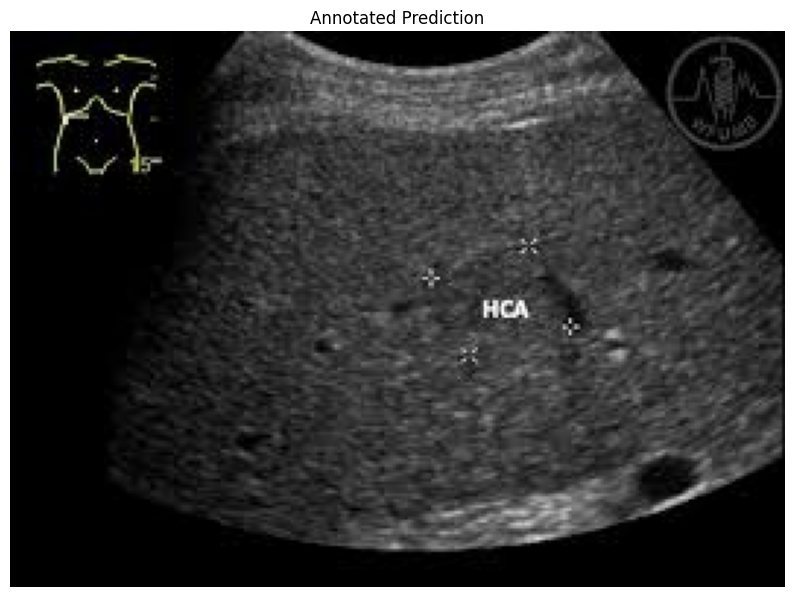

In [15]:
from pathlib import Path
from ultralytics import YOLO
from PIL import Image
import matplotlib.pyplot as plt
import json

# ============================================
# PATHS
# ============================================
MODEL_PATH = "/kaggle/working/runs/detect/train_yolo264/weights/best.pt"
IMAGE_PATH = "/kaggle/input/datasets/ahmedshayan1/yolo-liver-teset/images (1).jpg"

SAVE_DIR = Path("/kaggle/working/single_image_prediction")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ============================================
# SETTINGS
# ============================================
CONF_THRES = 0.25
IOU_THRES = 0.50

# ============================================
# LOAD MODEL
# ============================================
model = YOLO(MODEL_PATH)

# ============================================
# RUN INFERENCE
# ============================================
results = model.predict(
    source=IMAGE_PATH,
    conf=CONF_THRES,
    iou=IOU_THRES,
    save=True,
    project=str(SAVE_DIR),
    name="pred",
    exist_ok=True,
    verbose=False
)

r = results[0]

# ============================================
# PARSE RESULTS
# ============================================
detections = []

if len(r.boxes) > 0:
    confs = r.boxes.conf.cpu().numpy()
    classes = r.boxes.cls.cpu().numpy().astype(int)
    xyxy = r.boxes.xyxy.cpu().numpy()

    for i in range(len(r.boxes)):
        cls_id = int(classes[i])
        conf = float(confs[i])
        box = [float(x) for x in xyxy[i]]

        detections.append({
            "class_id": cls_id,
            "class_name": model.names[cls_id],
            "confidence": round(conf, 6),
            "box_xyxy": box
        })

    best_idx = confs.argmax()
    best_cls_id = int(classes[best_idx])
    best_conf = float(confs[best_idx])
    best_box = [float(x) for x in xyxy[best_idx]]

    best_detection = {
        "class_id": best_cls_id,
        "class_name": model.names[best_cls_id],
        "confidence": round(best_conf, 6),
        "box_xyxy": best_box
    }

else:
    best_detection = None

# ============================================
# FINAL OUTPUT JSON
# ============================================
annotated_image_path = SAVE_DIR / "pred" / Path(IMAGE_PATH).name

output = {
    "image_path": IMAGE_PATH,
    "model_path": MODEL_PATH,
    "num_detections": len(detections),
    "best_detection": best_detection,
    "detections": detections,
    "annotated_image_path": str(annotated_image_path)
}

print(json.dumps(output, indent=4))

# ============================================
# SHOW ANNOTATED IMAGE
# ============================================
if annotated_image_path.exists():
    img = Image.open(annotated_image_path)

    plt.figure(figsize=(10, 10))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Annotated Prediction")
    plt.show()
else:
    print("Annotated image not found:", annotated_image_path)

In [13]:
import shutil

source_folder = "/kaggle/working/runs/detect/train_yolo264"
output_zip = "/kaggle/working/train_yolo264"

shutil.make_archive(output_zip, "zip", source_folder)

print("ZIP created at:", output_zip + ".zip")

ZIP created at: /kaggle/working/train_yolo264.zip
